In [1]:
import numpy as np
import matplotlib.pyplot as plt

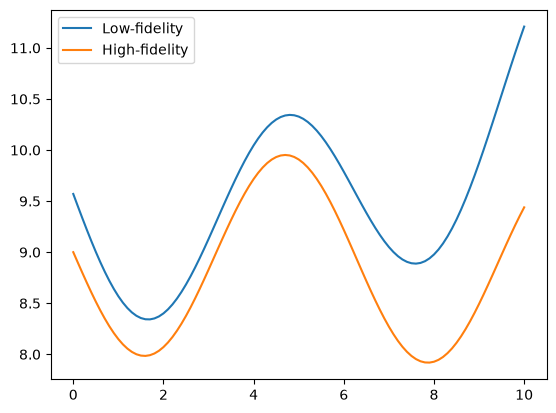

In [2]:


# high-fidelity function
def sasena2002_hf(x):
    return -np.sin(x)-np.exp(x/100)+10

# low-fidelity function
def sasena2002_lf(x):
    return sasena2002_hf(x)+0.3+0.03*(x-3)**2

bounds = np.array([
    [0, 10]
])

x_valid = np.linspace(bounds[0, 0], bounds[0, 1], 101)
y_hf = sasena2002_hf(x_valid)
y_lf = sasena2002_lf(x_valid)

fig, ax = plt.subplots()

ax.plot(x_valid, y_lf, label="Low-fidelity")
ax.plot(x_valid, y_hf, label="High-fidelity")

ax.legend()
plt.show()


[array([ 9.57      ,  8.40050123, 10.04599172,  9.78757895,  8.97735469,
       11.20885019]), array([9.31516352, 8.71772099])]


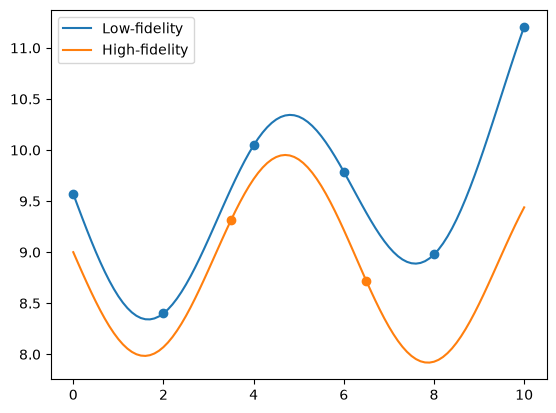

In [3]:


functions = [
    sasena2002_lf,
    sasena2002_hf
]

# xt = [
#     np.array([0., 2, 4, 6, 8, 10]),
#     np.array([2., 6, 8])
# ]
xt = [
    np.array([0., 2, 4, 6, 8, 10]),
    np.array([3.5, 6.5])
]

yt = []
for i, x in enumerate(xt):
    yt.append(functions[i](x))


print(yt)

fig, ax = plt.subplots()

ax.plot(x_valid, y_lf, label="Low-fidelity")
ax.plot(x_valid, y_hf, label="High-fidelity")


ax.scatter(xt[0], yt[0])
ax.scatter(xt[1], yt[1])

ax.legend()
plt.show()


In [4]:
import smt
print(smt.__file__)

c:\Data\RESEARCH\smt\smt\__init__.py


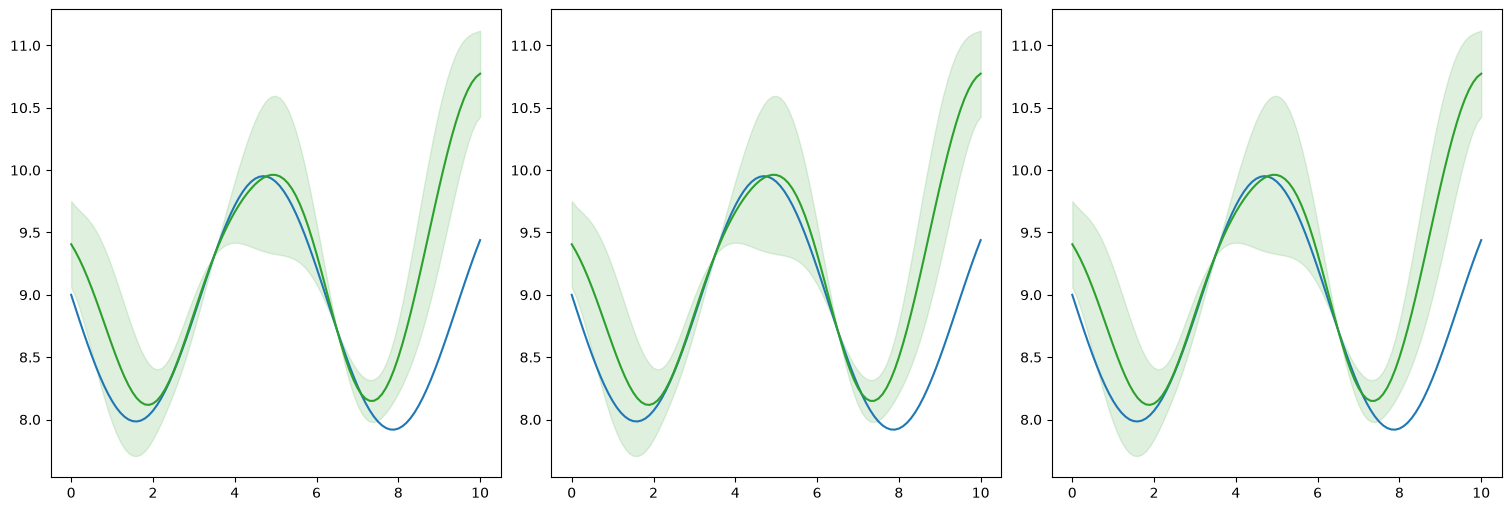

In [ ]:

from smt.applications import MFCK


sm = MFCK(print_global=False, hyper_opt="Cobyla", n_start=3, rho_bounds=[-10.., 10.], sequential_opt=False)

sm.set_training_values(xt[0].reshape(-1, 1), yt[0].reshape(-1, 1), name=0)
sm.set_training_values(xt[1].reshape(-1, 1), yt[1].reshape(-1, 1))

sm.train()

y_pred = sm.predict_values(x_valid.reshape(-1, 1)).ravel()


fig, ax = plt.subplots(1, 3, layout="constrained", figsize=(15, 5))

s2_pred = sm.predict_variances(x_valid.reshape(-1, 1)).ravel()
lower = y_pred - np.sqrt(s2_pred.ravel())
upper = y_pred + np.sqrt(s2_pred.ravel())
ax[0].plot(x_valid, y_hf)
ax[0].plot(x_valid, y_pred.reshape(-1, 1), color="C2")
ax[0].fill_between(x_valid, lower, upper, color="C2", alpha=0.15)

s2_pred = sm.predict_level_covariances(x_valid.reshape(-1, 1)).ravel()
lower = y_pred - np.sqrt(s2_pred.ravel())
upper = y_pred + np.sqrt(s2_pred.ravel())
ax[1].plot(x_valid, y_hf)
ax[1].plot(x_valid, y_pred.reshape(-1, 1), color="C2")
ax[1].fill_between(x_valid, lower, upper, color="C2", alpha=0.15)

s2_pred = sm.predict_variances(x_valid.reshape(-1, 1)).ravel()
lower = y_pred - np.sqrt(s2_pred.ravel())
upper = y_pred + np.sqrt(s2_pred.ravel())
ax[2].plot(x_valid, y_hf)
ax[2].plot(x_valid, y_pred.reshape(-1, 1), color="C2")
ax[2].fill_between(x_valid, lower, upper, color="C2", alpha=0.15)

plt.show()




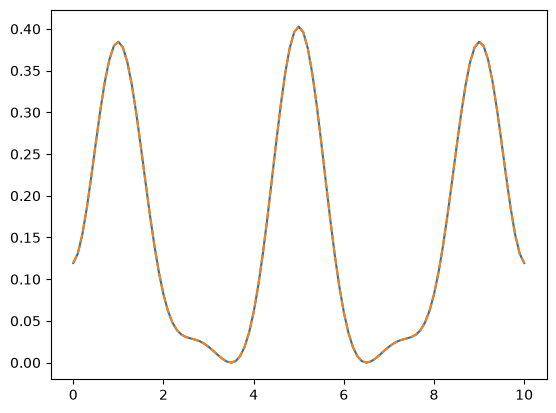

In [6]:


s2_pred = sm.predict_variances(x_valid.reshape(-1, 1)).ravel()
cov_pred = sm.predict_level_covariances(x_valid.reshape(-1, 1), lvli=1, lvlj=1).ravel()

fig, ax = plt.subplots()

ax.plot(x_valid, s2_pred)
ax.plot(x_valid, cov_pred, "--")
# ax.plot(x_valid, s2_pred_new, ".")

plt.show()


[7.76284518e-10]
1e-12


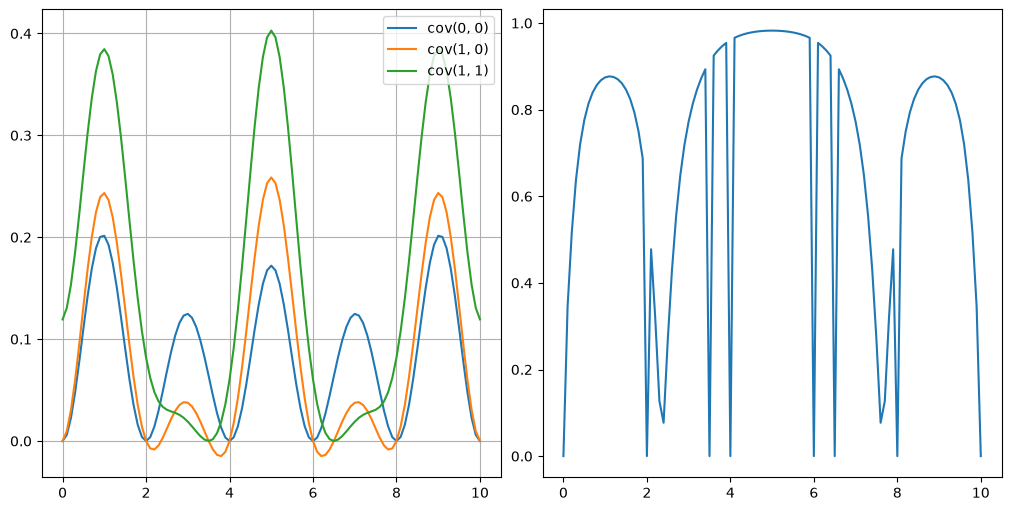

In [21]:


cov_00 = sm.predict_level_covariances(x_valid.reshape(-1, 1), lvli=0, lvlj=0).ravel()
# cov_01 = sm.predict_level_covariances(x_valid.reshape(-1, 1), lvli=0, lvlj=1).ravel()
cov_10 = sm.predict_level_covariances(x_valid.reshape(-1, 1), lvli=1, lvlj=0).ravel()
cov_11 = sm.predict_level_covariances(x_valid.reshape(-1, 1), lvli=1, lvlj=1).ravel()


corr_10 = cov_10 / np.sqrt(cov_00 * cov_11)
corr_10_clip = np.clip(np.abs(corr_10), 0, 1)

corr_11 = cov_11 / np.sqrt(cov_11 * cov_11)


eps = 1e-12 * max(cov_00.max(), cov_11.max())

print(sm.predict_variances(np.array([[3.5]])))
eps =  1e-12
print(eps)
corr_2 = np.where((cov_00 > eps) & (cov_11 > eps),
                cov_10 / np.sqrt(np.clip(cov_00, eps, None) * np.clip(cov_11, eps, None)),
                0.0)
# corr_2 = np.clip(corr_2, -1, 1)

fig, ax = plt.subplots(1, 2, layout="constrained", figsize=(10, 5))

ax[0].plot(x_valid, cov_00, label="cov(0, 0)")
ax[0].plot(x_valid, cov_10, label="cov(1, 0)")
ax[0].plot(x_valid, cov_11, label="cov(1, 1)")
ax[0].grid()
ax[0].legend()

# ax[1].plot(x_valid, corr_10)
ax[1].plot(x_valid, corr_10_clip, "-")
# ax[1].plot(x_valid, corr_11, "-.")
# ax[1].plot(x_valid, corr_2, ":")
# ax[1].plot(x_valid, corr_3, "--")

ax[1]

plt.show()